# Rapport - Moteur d'analyse de flux de logs sécurisé

**ING3 - Projet final Python**
Trinôme : *Nom Prénom 1* · *Nom Prénom 2* · *Nom Prénom 3*

Ce notebook sert uniquement à **montrer** le fonctionnement du projet et à tracer quelques graphiques. Tout le code « métier » est dans le package `log_engine/` et le pipeline complet se lance avec `python main.py`.

On suit l'ordre de l'énoncé : ingestion (générateurs) → transformations (filter/map/match-case) → agrégation (set, frozenset, defaultdict, détection de force brute) → moteur de règles et audit.

Le jeu de test est généré par `scripts/generer_logs.py` (3 fichiers de 15 000 lignes, avec volontairement des lignes cassées, du bruit et des attaques).

In [1]:
import sys
import tracemalloc
from collections import Counter
from datetime import timedelta
from itertools import islice
from pathlib import Path

import matplotlib.pyplot as plt

from log_engine.ingestion import lire_logs, lire_plusieurs_sources
from log_engine.parsing import parser_ligne
from log_engine.transformations import construire_pipeline, eclater, router
from log_engine.aggregation import agreger, charger_blacklist, comparer_ips, top
from log_engine.detection import afficher_alerte, collecter_tentatives, detecter_force_brute
from log_engine.regles import REGLES_PAR_DEFAUT, apply_security_rules
from log_engine.audit import auditer_contexte

FICHIERS = sorted(Path("data").glob("*.log"))
for f in FICHIERS:
    print(f"{f.name:<16} {f.stat().st_size / 1e6:.2f} Mo")

serveur_01.log   1.65 Mo
serveur_02.log   1.65 Mo
serveur_03.log   1.65 Mo


## 1. Ingestion avec des générateurs

`lire_logs` utilise `yield` : le fichier est ouvert, mais aucune ligne n'est lue tant qu'on ne demande rien. Pour enchaîner plusieurs fichiers, `lire_plusieurs_sources` délègue simplement avec `yield from`.

Petite comparaison entre un générateur et une liste qui contiendrait tout le fichier :

In [2]:
gen = lire_plusieurs_sources(FICHIERS)
print("Taille de l'objet générateur :", sys.getsizeof(gen), "octets")

# on ne consomme que 3 lignes, le reste n'est jamais lu
for ligne in islice(gen, 3):
    print(ligne)

Taille de l'objet générateur : 216 octets
2026-11-03 00:00:15 | INFO | 192.168.1.23:53/UDP | user=svc_backup | Cron job backup.sh finished
2026-11-03 00:00:25 | INFO | 192.168.1.13:80/HTTP | user=monitor | {"event": "healthcheck"}
2026-11-03 00:00:59 | INFO | 192.168.1.10:443/TCP | user=karim | {"event": "http", "path": "/login", "code": 200}


In [3]:
def pic_memoire(fonction):
    tracemalloc.start()
    fonction()
    _, pic = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return pic / 1024

# version naïve : on charge tout dans une liste
avec_liste = pic_memoire(lambda: len([l for f in FICHIERS
                                      for l in open(f, encoding="utf-8")]))
# version générateur : on compte en streaming
avec_generateur = pic_memoire(lambda: sum(1 for _ in lire_plusieurs_sources(FICHIERS)))

print(f"Liste      : {avec_liste:>9.0f} Ko")
print(f"Générateur : {avec_generateur:>9.0f} Ko")
print(f"-> environ {avec_liste / avec_generateur:.0f} fois moins de mémoire")

Liste      :      7040 Ko
Générateur :        31 Ko
-> environ 229 fois moins de mémoire


Avec la liste, la mémoire grandit avec la taille des fichiers. Avec le générateur elle reste à peu près constante : on pourrait traiter plusieurs Go de logs de la même façon.

### Parsing

Chaque ligne devient un dictionnaire. Les métadonnées de connexion `(IP, port, protocole)` sont stockées dans un **tuple** car elles ne doivent plus changer. Une ligne invalide renvoie `None` au lieu de lever une exception.

In [4]:
exemple = next(lire_logs(FICHIERS[0]))
record = parser_ligne(exemple)
for cle, valeur in record.items():
    print(f"{cle:<10} {type(valeur).__name__:<9} {valeur!r}")

print()
for mauvaise in ["2026-11-03 25:61:00 | INFO | 10.0.0.1:22/SSH | user=bob | test",
                 "2026-11-03 10:00:00 | ERROR | 300.12.1.1:22/SSH | user=bob | x",
                 "ligne totalement illisible"]:
    print(parser_ligne(mauvaise), "<-", mauvaise[:45])

timestamp  datetime  datetime.datetime(2026, 11, 3, 0, 0, 15)
level      str       'INFO'
source     tuple     ('192.168.1.23', 53, 'UDP')
ip         str       '192.168.1.23'
user       str       'svc_backup'
payload    str       'Cron job backup.sh finished'

None <- 2026-11-03 25:61:00 | INFO | 10.0.0.1:22/SSH 
None <- 2026-11-03 10:00:00 | ERROR | 300.12.1.1:22/S
None <- ligne totalement illisible


## 2. Pipeline fonctionnel

`construire_pipeline` enchaîne :

1. `filter(None, map(str.strip, lignes))` pour virer les lignes vides, puis un `filter` + `lambda` pour les commentaires ;
2. `map(parser_ligne, ...)` puis encore `filter(None, ...)` pour éliminer les lignes non parsables ;
3. `filter(est_requete_valide, ...)` : on retire les healthchecks et les payloads vides ;
4. `map(normaliser, ...)` : casse, espaces en trop, résumé formaté en f-string.

Tout reste paresseux jusqu'à la consommation finale.

In [5]:
lignes_brutes = sum(1 for _ in lire_plusieurs_sources(FICHIERS))
retenues = sum(1 for _ in construire_pipeline(lire_plusieurs_sources(FICHIERS)))
print(f"Lignes lues      : {lignes_brutes}")
print(f"Records retenus  : {retenues}")
print(f"Écartées         : {lignes_brutes - retenues} "
      f"({100 * (lignes_brutes - retenues) / lignes_brutes:.1f} %)")

pipeline = construire_pipeline(lire_plusieurs_sources(FICHIERS))
print()
for r in islice(pipeline, 4):
    print(r["resume"])

Lignes lues      : 45000
Records retenus  : 40023
Écartées         : 4977 (11.1 %)

[2026-11-03 00:00:15] INFO        192.168.1.23:53    UDP   user=svc_backup
[2026-11-03 00:00:59] INFO        192.168.1.10:443   TCP   user=karim
[2026-11-03 00:01:28] WARNING     192.168.1.54:80    HTTP  user=root
[2026-11-03 00:01:53] INFO      91.240.118.172:3306  TCP   user=bob


### Routage avec `match-case`

Un record est « éclaté » en éléments de formes différentes (dict de statut, tuple de connexion, chaîne brute) et la fonction `router` les classe uniquement grâce au pattern matching, sans aucun `isinstance` ni `if/elif`.

In [6]:
r = next(construire_pipeline(lire_plusieurs_sources(FICHIERS)))
for element in eclater(r):
    print(f"{str(element)[:45]:<47} -> {router(element)}")

print()
tests = [{"level": "CRITICAL", "code": 500}, {"level": "WARNING"},
         ("10.0.0.3", 23, "TELNET"), "Disk usage at 91%", 3.14]
for t in tests:
    print(f"{str(t):<35} -> {router(t)}")

{'level': 'INFO'}                               -> ('statut', 'INFO')
('192.168.1.23', 53, 'UDP')                     -> ('connexion', 'UDP 192.168.1.23:53')
Cron job backup.sh finished                     -> ('brut', 'Cron job backup.sh finished')

{'level': 'CRITICAL', 'code': 500}  -> ('erreur', 'CRITICAL code=500')
{'level': 'WARNING'}                -> ('statut', 'WARNING')
('10.0.0.3', 23, 'TELNET')          -> ('connexion_admin', 'TELNET 10.0.0.3:23')
Disk usage at 91%                   -> ('brut', 'Disk usage at 91%')
3.14                                -> ('inconnu', '3.14')


## 3. Agrégation

Un seul passage sur le flux remplit un objet `Statistiques` : des `set` pour les IP, des `defaultdict(int)` pour les compteurs (aucun `KeyError` possible).

In [7]:
stats = agreger(construire_pipeline(lire_plusieurs_sources(FICHIERS)))
print("Records :", stats.total)
print("Par niveau :", dict(stats.par_niveau))
print("Top utilisateurs :", top(stats.par_utilisateur, 5))
print("Catégories :", dict(stats.par_categorie))

Records : 40023
Par niveau : {'INFO': 29517, 'WARNING': 6201, 'CRITICAL': 892, 'ERROR': 3413}
Top utilisateurs : [('svc_backup', 3787), ('admin', 3748), ('alice', 3707), ('emma', 3653), ('root', 3638)]
Catégories : {'statut': 35718, 'connexion': 32751, 'brut': 9153, 'erreur': 4305, 'connexion_admin': 7272}


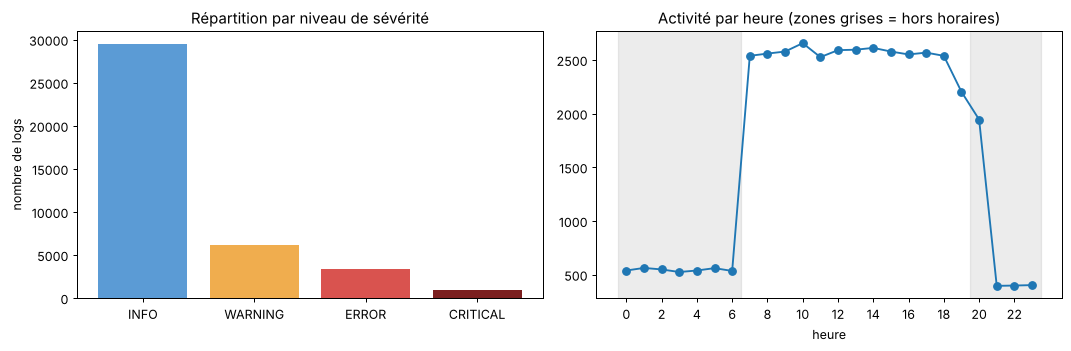

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

niveaux = ["INFO", "WARNING", "ERROR", "CRITICAL"]
couleurs = ["#5b9bd5", "#f0ad4e", "#d9534f", "#7b1f1f"]
axes[0].bar(niveaux, [stats.par_niveau[n] for n in niveaux], color=couleurs)
axes[0].set_title("Répartition par niveau de sévérité")
axes[0].set_ylabel("nombre de logs")

heures = range(24)
axes[1].plot(heures, [stats.par_heure[h] for h in heures], marker="o")
axes[1].axvspan(-0.5, 6.5, alpha=0.15, color="grey")
axes[1].axvspan(19.5, 23.5, alpha=0.15, color="grey")
axes[1].set_title("Activité par heure (zones grises = hors horaires)")
axes[1].set_xlabel("heure")
axes[1].set_xticks(range(0, 24, 2))

plt.tight_layout()
plt.show()

### Opérations ensemblistes

La blacklist est chargée en `frozenset` (elle ne doit pas être modifiée pendant l'analyse). On la croise avec l'ensemble des IP actives.

In [9]:
blacklist = charger_blacklist("data/blacklist.txt")
print("Type :", type(blacklist).__name__, "-", len(blacklist), "IP\n")

ensembles = comparer_ips(stats.ips_actives, blacklist)
symboles = {"union": "|", "intersection": "&", "actives_hors_blacklist": "-",
            "blacklist_inactives": "-", "difference_symetrique": "^"}
for nom, ips in ensembles.items():
    print(f"{symboles[nom]}  {nom:<24} {len(ips):>3} IP")

print("\nIP bannies qui ont quand même communiqué :", sorted(ensembles["intersection"]))

Type : frozenset - 5 IP

|  union                     87 IP
&  intersection               5 IP
-  actives_hors_blacklist    82 IP
-  blacklist_inactives        0 IP
^  difference_symetrique     82 IP

IP bannies qui ont quand même communiqué : ['185.220.101.4', '212.70.149.10', '45.155.205.233', '5.188.206.14', '91.240.118.172']


### Détection de force brute

On ne garde en mémoire que les tentatives de login (une petite fraction des logs), regroupées par IP. Ensuite :

- boucle `for` sur les IP, avec `continue` si une IP n'a même pas assez de tentatives ;
- boucle `while` qui avance dans les tentatives d'une IP ;
- boucle `for` interne qui compte les échecs consécutifs, avec `break` quand la fenêtre est dépassée ou qu'un succès arrive ;
- le `else` de cette boucle interne signifie « la série va jusqu'à la fin du journal » ;
- le `else` de la boucle externe valide que **toutes** les IP ont été analysées (sauf si on a coupé avec `max_alertes`).

In [10]:
tentatives = collecter_tentatives(construire_pipeline(lire_plusieurs_sources(FICHIERS)))
print("IP ayant tenté de se connecter :", len(tentatives))
print("Tentatives gardées en mémoire  :", sum(map(len, tentatives.values())))

alertes, complete = detecter_force_brute(tentatives, seuil=5,
                                         fenetre=timedelta(seconds=60))
print(f"\n{len(alertes)} alertes, analyse complète : {complete}\n")
for a in alertes[:8]:
    print(afficher_alerte(a))

# même chose en coupant volontairement à 3 alertes
_, complete = detecter_force_brute(tentatives, max_alertes=3)
print("\nAvec max_alertes=3 -> analyse complète :", complete)

IP ayant tenté de se connecter : 86
Tentatives gardées en mémoire  : 13577

28 alertes, analyse complète : True

 91.240.118.172 |  23 echecs en  38s | cibles : root | terminée
 91.240.118.172 |   6 echecs en  11s | cibles : admin | SUCCES juste apres (compte compromis ?)
  194.26.29.113 |  18 echecs en  25s | cibles : svc_backup | terminée
 45.155.205.233 |  25 echecs en  51s | cibles : alice | SUCCES juste apres (compte compromis ?)
 45.155.205.233 |   8 echecs en  14s | cibles : svc_backup | SUCCES juste apres (compte compromis ?)
 45.155.205.233 |  24 echecs en  42s | cibles : alice | terminée
 45.155.205.233 |  19 echecs en  36s | cibles : admin | terminée
  185.220.101.4 |  24 echecs en  42s | cibles : root | terminée

Avec max_alertes=3 -> analyse complète : False


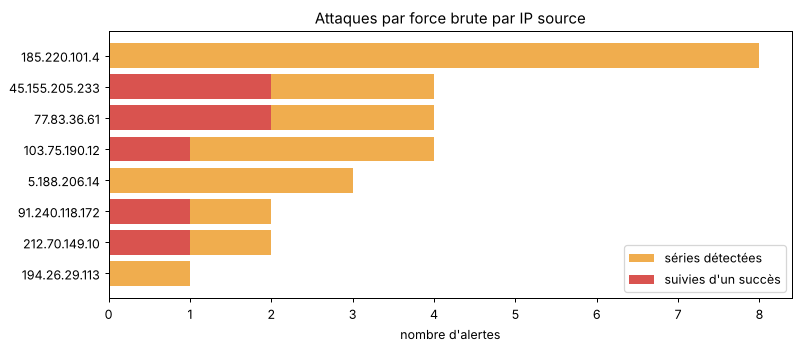

In [11]:
par_ip = Counter(a["ip"] for a in alertes)
compromis = Counter(a["ip"] for a in alertes if "SUCCES" in a["statut"])
ips = [ip for ip, _ in par_ip.most_common()]

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(ips, [par_ip[ip] for ip in ips], label="séries détectées", color="#f0ad4e")
ax.barh(ips, [compromis[ip] for ip in ips], label="suivies d'un succès", color="#d9534f")
ax.invert_yaxis()
ax.set_xlabel("nombre d'alertes")
ax.set_title("Attaques par force brute par IP source")
ax.legend()
plt.tight_layout()
plt.show()

L'influence des paramètres est logique : plus le seuil est bas, plus on détecte de séries (avec un risque de faux positifs sur un utilisateur qui se trompe plusieurs fois de mot de passe).

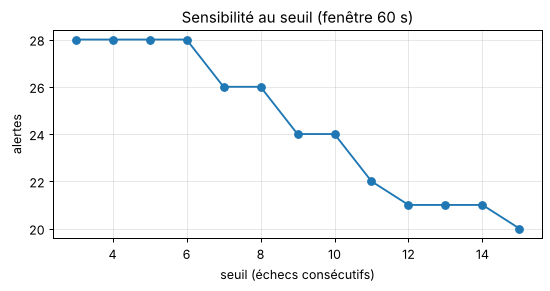

In [12]:
seuils = range(3, 16)
nb = [len(detecter_force_brute(tentatives, seuil=s)[0]) for s in seuils]
plt.figure(figsize=(7, 3))
plt.plot(list(seuils), nb, marker="o")
plt.xlabel("seuil (échecs consécutifs)")
plt.ylabel("alertes")
plt.title("Sensibilité au seuil (fenêtre 60 s)")
plt.grid(alpha=0.3)
plt.show()

## 4. Moteur de règles et introspection

`apply_security_rules(*args, **kwargs)` reçoit n'importe quel nombre de fonctions-règles dans `*args` et leur configuration dans `**kwargs`. Les fonctions sont donc traitées comme des objets de première classe. On peut même ajouter une règle à la volée avec une `lambda` :

In [13]:
resultats = apply_security_rules(
    *REGLES_PAR_DEFAUT,
    lambda r, **_: "FTP en clair" if r["source"][2] == "FTP" else None,
    records=construire_pipeline(lire_plusieurs_sources(FICHIERS)),
    blacklist=blacklist,
    heures_ouvrees=(8, 19),
    comptes_sensibles=frozenset({"root", "admin", "svc_backup"}),
    max_par_regle=2,
)
for nom, detail in sorted(resultats.items(), key=lambda kv: -kv[1]["total"]):
    print(f"{nom:<24} {detail['total']:>5}   ex: {detail['exemples'][0][:55]}")

regle_ip_blacklistee      4362   ex: IP blacklistée active : 91.240.118.172
regle_heure_nocturne      3332   ex: Connexion hors horaires (0h) de bob
<lambda>                  3152   ex: FTP en clair
regle_compte_sensible     3093   ex: Activité anormale sur compte sensible 'root'
regle_niveau_critique      892   ex: Evenement critique : [2026-11-03 00:03:43] CRITICAL    
regle_payload_suspect      882   ex: Motif d'injection '../../' depuis 10.0.0.28


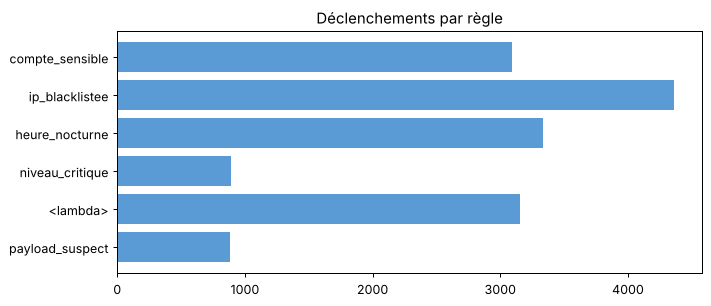

In [14]:
noms = list(resultats)
totaux = [resultats[n]["total"] for n in noms]
plt.figure(figsize=(8, 3.5))
plt.barh([n.replace("regle_", "") for n in noms], totaux, color="#5b9bd5")
plt.gca().invert_yaxis()
plt.title("Déclenchements par règle")
plt.tight_layout()
plt.show()

### Audit du contexte

`auditer_contexte` reçoit `globals()` et `locals()` de l'appelant (une fonction ne peut pas lire les variables locales d'une autre), filtre les modules et les noms internes, puis décrit chaque variable (type, taille, aperçu). Dans `main.py` le rapport est exporté dans `output/audit.json`.

In [15]:
def etape_de_test():
    seuil = 5
    ips_suspectes = set(ensembles["intersection"])
    return auditer_contexte(globals(), locals(), etape="démo notebook")

rapport = etape_de_test()
print("Globales :", rapport["nb_globales"], "| Locales :", rapport["nb_locales"])
for v in rapport["locales"]:
    print(f"  {v['nom']:<14} {v['type']:<10} {v['taille_octets']:>5} o  {v['apercu'][:40]}")

Globales : 61 | Locales : 2
  ips_suspectes  set          472 o  {'91.240.118.172', '5.188.206.14', '212.
  seuil          int           28 o  5


## 5. Lancement complet et tests

```bash
python main.py                          # pipeline complet sur data/*.log
python main.py --seuil 8 --fenetre 30   # autres paramètres
python main.py --memoire                # mesure du pic mémoire
python -m unittest -v                   # 15 tests unitaires
```

## Conclusion

- **Mémoire** : tout est en flux (`yield`, `yield from`, `map`, `filter`). Le seul choix assumé est de relire les fichiers pour chaque analyse plutôt que de garder les données : un générateur ne se consomme qu'une fois, et relire coûte du temps mais pas de RAM.
- **Structures** : tuple pour les métadonnées fixes, `frozenset` pour la blacklist, `set` pour les IP uniques, `defaultdict` pour tous les compteurs, `match-case` pour le routage.
- **Robustesse** : une ligne cassée renvoie `None`, un fichier absent est ignoré avec un avertissement, une règle qui plante n'arrête pas les autres.

**Limites / pistes** : le parseur ne gère qu'un format de ligne ; on pourrait lire un vrai flux réseau (socket) à la place des fichiers, puisque le reste du pipeline accepte n'importe quel itérable de chaînes. La détection de force brute pourrait aussi regrouper par utilisateur ciblé et pas seulement par IP (attaques distribuées).